# Poisson Distribution

Companion notebook for the [Poisson distribution note](../../notes/random_variables_and_distributions/discrete/poisson_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/poisson_distribution.md).

$X\sim\text{Poisson}(\lambda)$ counts events in a fixed interval when events occur independently at a constant average rate:

$$P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!},\qquad E[X]=\operatorname{Var}(X)=\lambda.$$

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

In [2]:
class PoissonDistribution:
    def __init__(self, lam):
        self.lam = lam

    def pmf(self, k):
        k = np.asarray(k)
        return np.array([self.lam**i * math.exp(-self.lam) / math.factorial(int(i))
                         for i in k.ravel()]).reshape(k.shape)

    def cdf(self, k):
        k = np.asarray(k)
        cum = np.cumsum(self.pmf(np.arange(int(k.max()) + 1)))
        return cum[k.astype(int)]

## Check against `scipy.stats`

In [3]:
lam1, lam2 = 3, 5
k = np.arange(0, 16)
d1, d2 = PoissonDistribution(lam1), PoissonDistribution(lam2)

pmf1, pmf2 = stats.poisson.pmf(k, lam1), stats.poisson.pmf(k, lam2)
cdf1, cdf2 = stats.poisson.cdf(k, lam1), stats.poisson.cdf(k, lam2)
print("PMF matches:", np.allclose(d1.pmf(k), pmf1), np.allclose(d2.pmf(k), pmf2))
print("CDF matches:", np.allclose(d1.cdf(k), cdf1), np.allclose(d2.cdf(k), cdf2))
print("mean = var:", stats.poisson.mean(lam2), stats.poisson.var(lam2))

PMF matches: True True
CDF matches: True True
mean = var: 5.0 5.0


## Shape of the PMF and CDF

For small $\lambda$ the PMF is right-skewed with its mode at 0 or 1; as $\lambda$ grows it becomes more symmetric. Note that for integer $\lambda$ the values $\lambda-1$ and $\lambda$ are both modes.

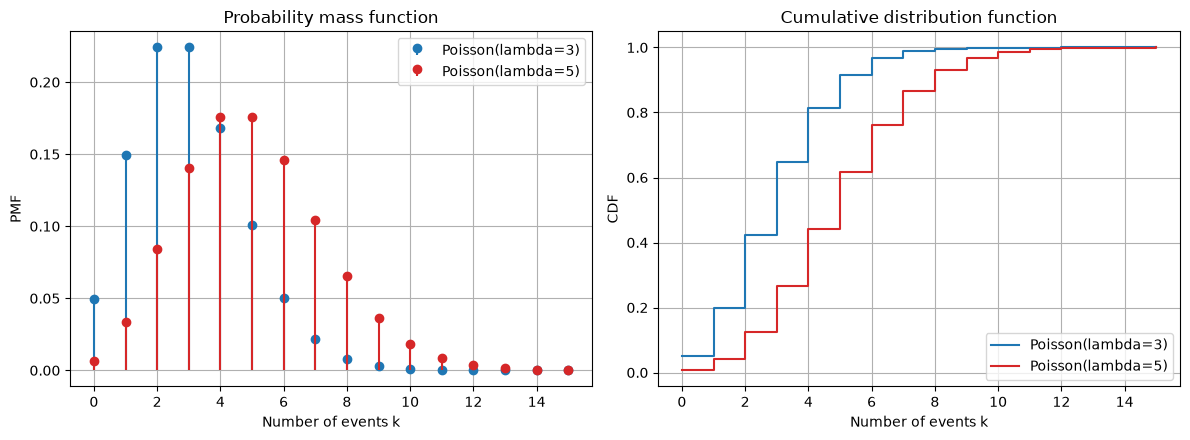

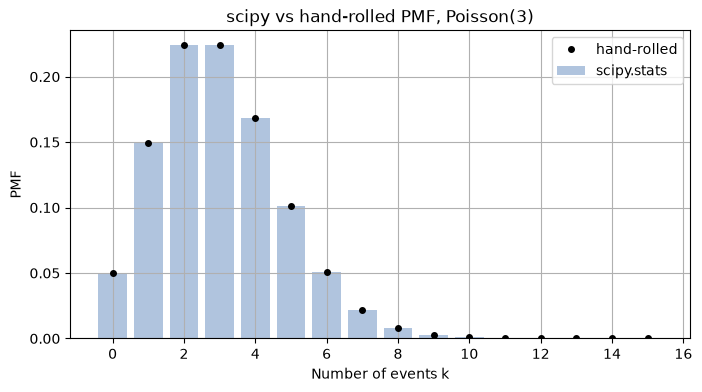

In [4]:
def plot_pmf_cdf(x1, pmf1, cdf1, label1, x2, pmf2, cdf2, label2, xlabel):
    """PMF (stem) and CDF (step) of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.stem(x1, pmf1, basefmt=" ", linefmt="C0-", markerfmt="C0o", label=label1)
    ax1.stem(x2, pmf2, basefmt=" ", linefmt="C3-", markerfmt="C3o", label=label2)
    ax1.set(xlabel=xlabel, ylabel="PMF", title="Probability mass function")
    ax2.step(x1, cdf1, where="post", color="C0", label=label1)
    ax2.step(x2, cdf2, where="post", color="C3", label=label2)
    ax2.set(xlabel=xlabel, ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, xlabel, title):
    """Hand-rolled values (dots) on top of the scipy.stats values (bars)."""
    plt.figure(figsize=(8, 4))
    plt.bar(x, ref, color="lightsteelblue", label="scipy.stats")
    plt.plot(x, custom, "ko", markersize=4, label="hand-rolled")
    plt.xlabel(xlabel)
    plt.ylabel("PMF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pmf_cdf(k, pmf1, cdf1, f"Poisson(lambda={lam1})", k, pmf2, cdf2, f"Poisson(lambda={lam2})", "Number of events k")
plot_overlay(k, pmf1, d1.pmf(k), "Number of events k", "scipy vs hand-rolled PMF, Poisson(3)")

## Worked example: emergency room visits

From the note: on average 5 visits per hour, $\lambda=5$. Because rates scale with the interval, a 30-minute window has $\lambda=2.5$.

In [5]:
er = PoissonDistribution(5)
print(f"P(X = 3)  = {er.pmf(3):.4f}")
print(f"P(X > 7)  = {1 - er.cdf(7):.4f}")
print(f"P(X <= 2) = {er.cdf(2):.4f}")
half_hour = PoissonDistribution(2.5)
print(f"P(no visits in 30 min) = {half_hour.pmf(0):.4f}   exp(-2.5) = {math.exp(-2.5):.4f}")

P(X = 3)  = 0.1404
P(X > 7)  = 0.1334
P(X <= 2) = 0.1247
P(no visits in 30 min) = 0.0821   exp(-2.5) = 0.0821


## Poisson approximation to the binomial

For large $n$ and small $p$, $\text{Binomial}(n,p)\approx\text{Poisson}(np)$. We compare the two PMFs for $n=500$, $p=0.01$ ($\lambda=5$).

max |binomial - Poisson| = 0.00088


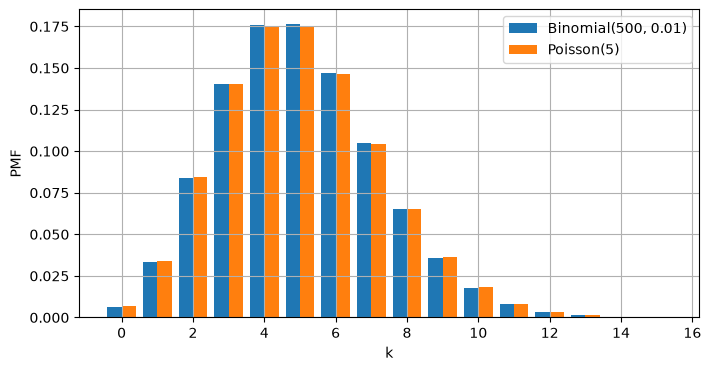

In [6]:
n, p = 500, 0.01
j = np.arange(0, 16)
binom_pmf = stats.binom.pmf(j, n, p)
pois_pmf = stats.poisson.pmf(j, n * p)
print(f"max |binomial - Poisson| = {np.abs(binom_pmf - pois_pmf).max():.5f}")

plt.figure(figsize=(8, 4))
plt.bar(j - 0.2, binom_pmf, width=0.4, label="Binomial(500, 0.01)")
plt.bar(j + 0.2, pois_pmf, width=0.4, label="Poisson(5)")
plt.xlabel("k")
plt.ylabel("PMF")
plt.legend()
plt.grid(True)
plt.show()

## Simulation versus theory

A seeded sample of 100,000 counts: the sample mean and variance should both be near $\lambda$ (the dispersion index variance/mean should be near 1).

mean 4.995, var 4.983, dispersion index 0.998


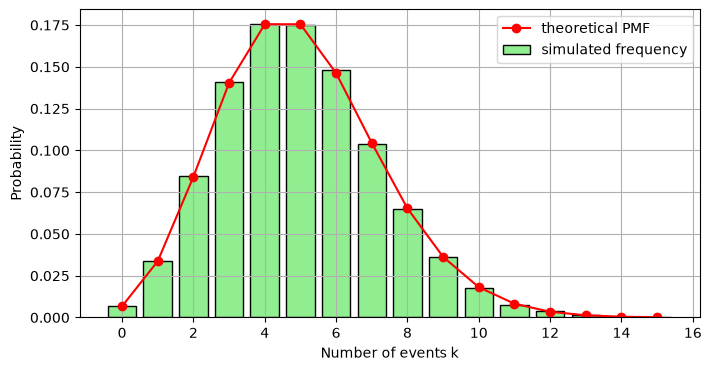

In [7]:
sample = rng.poisson(lam2, size=100_000)
print(f"mean {sample.mean():.3f}, var {sample.var():.3f}, dispersion index {sample.var() / sample.mean():.3f}")

freq = np.bincount(sample, minlength=16)[:16] / sample.size
plt.figure(figsize=(8, 4))
plt.bar(k, freq, color="lightgreen", edgecolor="black", label="simulated frequency")
plt.plot(k, d2.pmf(k), "ro-", label="theoretical PMF")
plt.xlabel("Number of events k")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

## Takeaways

* Mean and variance both equal $\lambda$; a dispersion index far from 1 signals over- or under-dispersion.
* Rates scale linearly with the length of the observation window.
* The binomial with large $n$ and small $p$ is well approximated by Poisson($np$).